# Notebook 3: DistilBERT fine-tuning

This notebook uses these .csv files:
- `headlines_train.csv`
- `headlines_validation.csv`
- `headlines_test.csv`

It trains or loads an explicitly selected fine-tuned model version. It reports preliminary metrics on the validation set, then also evaluates the test set if `RUN_TEST_EVALUATION` is enabled.

Required columns: `headline` and `label`, with `0 = non-clickbait/news`, `1 = clickbait`.


## 1. Choose a GPU runtime in Colab

In Colab, select **Runtime → Change runtime type → GPU** if one is available. GPU availability varies. Training can run on CPU, but it will be slower.


In [1]:
%pip -q install transformers==4.50.3 accelerate datasets scikit-learn seaborn


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import torch
from datasets import Dataset
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_recall_fscore_support
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)

set_seed(42)
print('CUDA available:', torch.cuda.is_available())
print('Device:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')


CUDA available: True
Device: Tesla T4


## 2. Mount Google Drive and choose train or load

Drive is mounted as a folder path in Colab; it is not a URL. Upload all three CSV files in `MyDrive/clickbait_project/datasets/`.

- First run: keep `MODEL_ACTION = 'train'`. It starts from the pretrained DistilBERT model, fine-tunes it, and saves the result to Drive.
- Later/demo run: set `MODEL_ACTION = 'load'` to load that saved version without training.
- To make an updated model, choose a new version name (for example `distilbert_v2`) and set action to `train`. The notebook will not overwrite an existing model version.


In [3]:
from pathlib import Path

# Choose where this notebook reads data and saves/loads models.
STORAGE_MODE = "drive"  # Choose: "drive" for Colab, "local" for Jupyter on your computer

if STORAGE_MODE == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/clickbait_project")

elif STORAGE_MODE == "local":
    # Expected layout: project/datasets, project/models, project/results, project/notebooks
    PROJECT_DIR = Path.cwd().resolve()
    if PROJECT_DIR.name.lower() == "notebooks":
        PROJECT_DIR = PROJECT_DIR.parent

    # If needed, set your project folder explicitly, for example:
    # PROJECT_DIR = Path(r"C:\Users\YourName\clickbait-project")

else:
    raise ValueError("STORAGE_MODE must be 'drive' or 'local'.")

DATA_DIR = PROJECT_DIR / "datasets"
MODELS_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"

MODEL_ACTION = "train"  # Choose: "train" or "load"
MODEL_VERSION = "distilbert_v1"
MODEL_DIR = MODELS_DIR / MODEL_VERSION

TRAIN_PATH = DATA_DIR / "headlines_train.csv"
VALIDATION_PATH = DATA_DIR / "headlines_validation.csv"
TEST_PATH = DATA_DIR / "headlines_test.csv"

RUN_TEST_EVALUATION = True

if MODEL_ACTION not in {"train", "load"}:
    raise ValueError("MODEL_ACTION must be 'train' or 'load'.")

if MODEL_ACTION == "train" and MODEL_DIR.exists():
    raise FileExistsError(
        f"{MODEL_DIR} already exists. Choose a new MODEL_VERSION to preserve the existing model."
    )

if MODEL_ACTION == "load" and not MODEL_DIR.exists():
    raise FileNotFoundError(
        f"No saved model at {MODEL_DIR}. Train that version first or correct MODEL_VERSION."
    )

# Create the data folder if it doesn't exist yet.
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Validation and training data are always needed. Test data is needed if test evaluation is enabled.
required_paths = [TRAIN_PATH, VALIDATION_PATH]
if RUN_TEST_EVALUATION:
    required_paths.append(TEST_PATH)

missing_paths = [path for path in required_paths if not path.exists()]

if missing_paths:
    try:
        from google.colab import files
    except ImportError:
        names = ", ".join(path.name for path in missing_paths)
        raise FileNotFoundError(
            f"Missing {names}. Put these files in {DATA_DIR} and rerun this cell."
        )

    print("Upload the missing CSV files:", ", ".join(path.name for path in missing_paths))
    uploaded_files = files.upload()

    # Copy only the missing files with the expected names into DATA_DIR.
    for path in missing_paths:
        if path.name in uploaded_files:
            path.write_bytes(uploaded_files[path.name])

    missing_paths = [path for path in required_paths if not path.exists()]
    if missing_paths:
        raise FileNotFoundError(
            "Still missing: " + ", ".join(path.name for path in missing_paths)
        )

print("Action:", MODEL_ACTION)
print("Model version:", MODEL_VERSION)
print("Model path:", MODEL_DIR)
print("Dataset folder:", DATA_DIR)

Mounted at /content/drive
Upload the missing CSV files: headlines_train.csv, headlines_validation.csv, headlines_test.csv


Saving headlines_test.csv to headlines_test.csv
Saving headlines_train.csv to headlines_train.csv
Saving headlines_validation.csv to headlines_validation.csv
Action: train
Model version: distilbert_v1
Model path: /content/drive/MyDrive/clickbait_project/models/distilbert_v1
Dataset folder: /content/drive/MyDrive/clickbait_project/datasets


## 3. Load and check the splits

This cell verifies column names and binary labels. It does not combine or reshuffle the files. Both model notebooks should use these same train and validation files.


In [4]:
def read_split(path, split_name):
    frame = pd.read_csv(path, encoding='utf-8-sig')
    required = {'headline', 'label'}
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f'{path.name} is missing columns: {sorted(missing)}')
    frame = frame[['headline', 'label']].dropna().copy()
    frame['headline'] = frame['headline'].astype(str).str.strip()
    frame = frame[frame['headline'].ne('')].copy()
    frame['label'] = pd.to_numeric(frame['label'], errors='raise').astype(int)
    if not set(frame['label'].unique()).issubset({0, 1}):
        raise ValueError(f'{path.name} labels must be 0/1; found {sorted(frame["label"].unique())}')
    frame = frame.reset_index(drop=True)
    print(f'{split_name}: {len(frame):,} rows')
    display(frame['label'].value_counts().sort_index().rename_axis('label').to_frame('rows'))
    return frame

train_df = read_split(TRAIN_PATH, 'Training split')
validation_df = read_split(VALIDATION_PATH, 'Validation split')
test_df = read_split(TEST_PATH, 'Test split') if RUN_TEST_EVALUATION else None
print('Label mapping: 0 = non-clickbait/news; 1 = clickbait')


Training split: 40,208 rows


,rows
label,
0,24446
1,15762


Validation split: 5,027 rows


,rows
label,
0,3056
1,1971


Test split: 5,026 rows


,rows
label,
0,3056
1,1970


Label mapping: 0 = non-clickbait/news; 1 = clickbait


## 4. Tokenize text and load the model

Fine-tuning starts with the existing pretrained DistilBERT weights and adapts them to the two labels. The model is not trained from scratch. Headline length and training settings below are intentionally modest and fixed.


In [5]:
BASE_MODEL = 'distilbert/distilbert-base-uncased'
MAX_LENGTH = 64
BATCH_SIZE = 16
EPOCHS = 2
LEARNING_RATE = 2e-5

if MODEL_ACTION == 'train':
    tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)
    model = AutoModelForSequenceClassification.from_pretrained(
        BASE_MODEL,
        num_labels=2,
        id2label={0: 'non-clickbait/news', 1: 'clickbait'},
        label2id={'non-clickbait/news': 0, 'clickbait': 1},
    )
else:
    tokenizer = AutoTokenizer.from_pretrained(str(MODEL_DIR), local_files_only=True)
    model = AutoModelForSequenceClassification.from_pretrained(str(MODEL_DIR), local_files_only=True)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

def make_hf_dataset(frame):
    raw = Dataset.from_pandas(
        pd.DataFrame({'text': frame['headline'], 'labels': frame['label']}),
        preserve_index=False,
    )
    return raw.map(
        lambda batch: tokenizer(batch['text'], truncation=True, max_length=MAX_LENGTH),
        batched=True,
        remove_columns=['text'],
    )

train_hf = make_hf_dataset(train_df)
validation_hf = make_hf_dataset(validation_df)
test_hf = make_hf_dataset(test_df) if RUN_TEST_EVALUATION else None
print('Tokenization complete.')


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert/distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Map:   0%|          | 0/40208 [00:00<?, ? examples/s]

Map:   0%|          | 0/5027 [00:00<?, ? examples/s]

Map:   0%|          | 0/5026 [00:00<?, ? examples/s]

Tokenization complete.


## 5. Train and save, or load the selected version

When `MODEL_ACTION` is `train`, the trainer sees only `headlines_train.csv`. Validation and test rows are not used to update weights. After training, the model and tokenizer are saved to the versioned Drive folder.


In [6]:
training_args = TrainingArguments(
    output_dir='/content/distilbert_training_temp',
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE,
    weight_decay=0.01,
    logging_steps=100,
    save_strategy='no',
    report_to='none',
    seed=42,
    fp16=torch.cuda.is_available(),
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_hf if MODEL_ACTION == 'train' else None,
    data_collator=data_collator,
    processing_class=tokenizer,
)

if MODEL_ACTION == 'train':
    train_result = trainer.train()
    print('Training complete.')
    print(train_result.metrics)
    MODEL_DIR.mkdir(parents=True, exist_ok=False)
    trainer.save_model(str(MODEL_DIR))
    tokenizer.save_pretrained(str(MODEL_DIR))
    print('Saved model and tokenizer to:', MODEL_DIR)
else:
    print('Loaded saved model; training was skipped.')


Step,Training Loss
100,0.369700
200,0.254600
300,0.247900
400,0.283100
500,0.277700
600,0.235800
700,0.250800
800,0.231900
900,0.229900
1000,0.232000


Training complete.
{'train_runtime': 291.2939, 'train_samples_per_second': 276.065, 'train_steps_per_second': 17.254, 'total_flos': 528685667248512.0, 'train_loss': 0.20620550551454336, 'epoch': 2.0}
Saved model and tokenizer to: /content/drive/MyDrive/clickbait_project/models/distilbert_v1


## 6. Evaluate on validation (preliminary results)

These are the metrics to use for preliminary results and model improvements. The clickbait class is label 1. Inspect false positives and false negatives below.


{
  "split": "validation",
  "accuracy": 0.9204296797294609,
  "clickbait_precision": 0.908051948051948,
  "clickbait_recall": 0.8868594622019279,
  "clickbait_f1": 0.8973305954825462,
  "rows": 5027,
  "model_version": "distilbert_v1"
}
                    precision    recall  f1-score   support

non-clickbait/news       0.93      0.94      0.94      3056
         clickbait       0.91      0.89      0.90      1971

          accuracy                           0.92      5027
         macro avg       0.92      0.91      0.92      5027
      weighted avg       0.92      0.92      0.92      5027



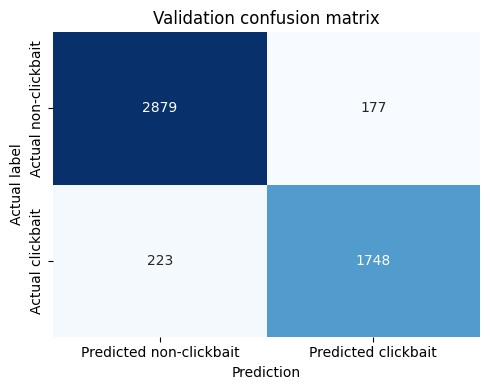

In [7]:
def evaluate_split(frame, hf_dataset, split_name):
    output = trainer.predict(hf_dataset)
    probs = torch.softmax(torch.tensor(output.predictions), dim=1).cpu().numpy()
    y_true = frame['label'].to_numpy()
    y_pred = probs.argmax(axis=1)
    clickbait_probability = probs[:, 1]
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=[1], average='binary', zero_division=0
    )
    metrics = {
        'split': split_name,
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'clickbait_precision': float(precision),
        'clickbait_recall': float(recall),
        'clickbait_f1': float(f1),
        'rows': int(len(frame)),
        'model_version': MODEL_VERSION,
    }
    predictions = frame.copy()
    predictions['predicted_label'] = y_pred
    predictions['clickbait_confidence_percent'] = (clickbait_probability * 100).round(2)
    print(json.dumps(metrics, indent=2))
    print(classification_report(
        y_true, y_pred, labels=[0, 1],
        target_names=['non-clickbait/news', 'clickbait'], zero_division=0
    ))
    matrix = confusion_matrix(y_true, y_pred, labels=[0, 1])
    plt.figure(figsize=(5, 4))
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Predicted non-clickbait', 'Predicted clickbait'],
                yticklabels=['Actual non-clickbait', 'Actual clickbait'])
    plt.title(f'{split_name.title()} confusion matrix')
    plt.xlabel('Prediction')
    plt.ylabel('Actual label')
    plt.tight_layout()
    plt.show()
    return metrics, predictions

validation_metrics, validation_predictions = evaluate_split(
    validation_df, validation_hf, 'validation'
)


In [8]:
validation_errors = validation_predictions[
    validation_predictions['label'] != validation_predictions['predicted_label']
]
print('Validation errors:', len(validation_errors))
display(validation_errors[['headline', 'label', 'predicted_label', 'clickbait_confidence_percent']].head(20))


Validation errors: 400


,headline,label,predicted_label,clickbait_confidence_percent
13,"When it comes to Israel, stakes are high for J...",1,0,0.410000
28,John Legend Kissing Chrissy Teigen's Baby Bump...,1,0,22.510000
32,'Bachelor' Contestants Respond To Claims That ...,0,1,68.339996
51,School Suspends 12-Year-Old Boy Attacked on Bu...,1,0,11.720000
52,Why are TV baddies always weird white men? Sub...,1,0,23.650000
55,Women's sport proves the best buy for business,1,0,3.840000
65,'I prefer to orgasm and get paid': Brazilian l...,1,0,15.400000
69,Hoping for an Inheritance? You May Not Get as ...,1,0,13.130000
84,"Kerry Ingram, AKA Shireen From 'Game Of Throne...",1,0,2.740000
108,Here Are 5 Things You May Not Know About India...,0,1,99.279999


## 7. Optional test-set observation

This cell evaluates `headline_test.csv` when `RUN_TEST_EVALUATION = True`. The test file has already been accessed in prior work, and this run accesses it again. Treat these numbers as observational; do not use them to choose settings or make improvements. Use validation results for that.


{
  "split": "test",
  "accuracy": 0.9056904098686829,
  "clickbait_precision": 0.8978723404255319,
  "clickbait_recall": 0.8568527918781725,
  "clickbait_f1": 0.8768831168831169,
  "rows": 5026,
  "model_version": "distilbert_v1"
}
                    precision    recall  f1-score   support

non-clickbait/news       0.91      0.94      0.92      3056
         clickbait       0.90      0.86      0.88      1970

          accuracy                           0.91      5026
         macro avg       0.90      0.90      0.90      5026
      weighted avg       0.91      0.91      0.91      5026



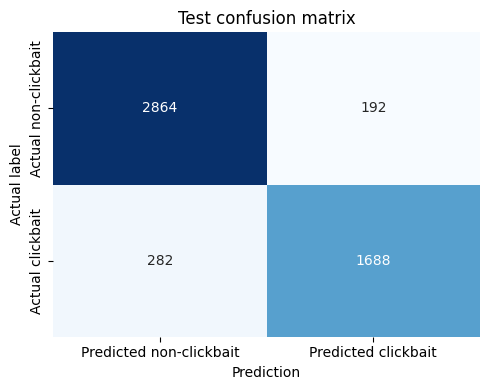

Test errors: 474


,headline,label,predicted_label,clickbait_confidence_percent
1,Singles Try To Explain Cuffing Season,1,0,4.910000
18,People Are Shook Over How Hot Young Justin Tru...,0,1,99.480003
19,The Force Is Strong With This Family's BB-8 Sn...,0,1,91.510002
24,Will the Real Democracy Lovers Please Stand Up?,1,0,41.580002
40,The gadget that makes Taylor Swift sound pitch...,0,1,60.099998
42,Why Does Mount Rushmore Exist?,1,0,27.830000
57,How Theresa May's childhood heroine inspired h...,1,0,1.630000
67,"The BBC Kids and Their Parents Are Back, in a ...",0,1,73.800003
81,Storms Have Unveiled A Shipwreck From The 1930...,1,0,1.520000
90,Personal spending jumps by the most in 3 months,1,0,1.860000


In [9]:
test_metrics = None
if RUN_TEST_EVALUATION:
    test_metrics, test_predictions = evaluate_split(test_df, test_hf, 'test')
    test_errors = test_predictions[test_predictions['label'] != test_predictions['predicted_label']]
    print('Test errors:', len(test_errors))
    display(test_errors[['headline', 'label', 'predicted_label', 'clickbait_confidence_percent']].head(20))
else:
    print('Test evaluation skipped.')


## 8. Save metrics and predictions to Drive

Validation results are saved for your preliminary presentation. Test results are also saved if the optional test evaluation is enabled. Confidence is the model's estimated clickbait probability, not a verified measure of how misleading a headline is.


In [10]:
RESULT_VERSION_DIR = RESULTS_DIR / MODEL_VERSION
RESULT_VERSION_DIR.mkdir(parents=True, exist_ok=True)

with open(RESULT_VERSION_DIR / 'validation_metrics.json', 'w', encoding='utf-8') as f:
    json.dump(validation_metrics, f, indent=2)
validation_predictions.to_csv(
    RESULT_VERSION_DIR / 'validation_predictions.csv', index=False, encoding='utf-8-sig'
)

if test_metrics is not None:
    with open(RESULT_VERSION_DIR / 'test_metrics_observational.json', 'w', encoding='utf-8') as f:
        json.dump(test_metrics, f, indent=2)
    test_predictions.to_csv(
        RESULT_VERSION_DIR / 'test_predictions_observational.csv', index=False, encoding='utf-8-sig'
    )

print('Saved results to:', RESULT_VERSION_DIR)


Saved results to: /content/drive/MyDrive/clickbait_project/results/distilbert_v1


## Settings used in this run

- Base model: `distilbert/distilbert-base-uncased`
- Training epochs: 2
- Maximum headline length: 64 tokens
- Batch size: 16
- Learning rate: 2e-5
- Random seed: 42
- Train split: `headlines_train.csv`
- Preliminary evaluation: `headline_validation.csv`
- Optional observation: `headline_test.csv`

For another training experiment, use `MODEL_ACTION = 'train'` and a new version name such as `distilbert_v2`. The notebook will preserve the earlier Drive model.
